In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import save_image
from tqdm import tqdm

class VAE(nn.Module):
    def __init__(self, latent_dim=100):
        super(VAE, self).__init__()
        self.latent_dim = latent_dim
        
        # Encoder
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1),  # Same padding
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),  # Reduce spatial dimensions
            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(128, 256, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Flatten(),
            nn.Linear(256*4*4, self.latent_dim * 2)  # Output mu and log_var
        )
        
        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(self.latent_dim, 256*4*4),
            nn.ReLU(),
            nn.Unflatten(1, (256, 4, 4)),
            nn.ConvTranspose2d(256, 128, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(128, 64, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(64, 3, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.Sigmoid()  # Ensure output is between [0, 1]
        )

    def reparameterize(self, mu, log_var):
        std = torch.exp(0.5 * log_var)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        encoded = self.encoder(x)
        mu, log_var = torch.chunk(encoded, 2, dim=1)  # Split encoded values into mu and log_var
        z = self.reparameterize(mu, log_var)
        return self.decoder(z), mu, log_var

def train(model, data_loader, optimizer):
    model.train()
    for idx, (images, _) in enumerate(data_loader):
        images = images.to(device)
        optimizer.zero_grad()
        reconstructed, mu, log_var = model(images)
        loss = vae_loss(images, reconstructed, mu, log_var)
        loss.backward()
        optimizer.step()

def vae_loss(true, recon, mu, log_var):
    recon_loss = nn.functional.mse_loss(recon, true, reduction='sum')
    kl_div = -0.5 * torch.sum(1 + log_var - mu.pow(2) - log_var.exp())
    return recon_loss + kl_div

device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = VAE().to(device)
optimizer = optim.Adam(model.parameters(), lr=0.001)
transform = transforms.Compose([transforms.ToTensor()])
train_dataset = datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

# Train the model
epochs = 50
for epoch in tqdm(range(epochs)):
    train(model, train_loader, optimizer)

Files already downloaded and verified


100%|██████████| 50/50 [15:02<00:00, 18.04s/it]


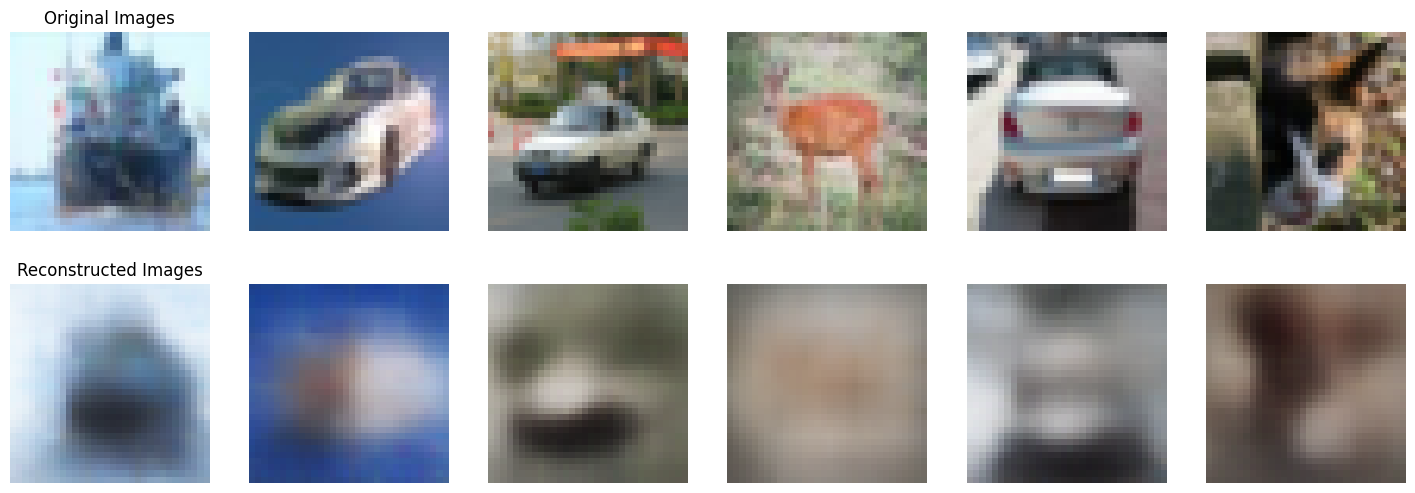

In [9]:
import matplotlib.pyplot as plt

def visualize_reconstructions(model, data_loader, num_images=6):
    model.eval()  # Set the model to evaluation mode
    images, _ = next(iter(data_loader))  # Get a batch of images from the data loader
    images = images.to(device)[:num_images]  # Move images to the device and limit the number of images
    with torch.no_grad():  # Inference without gradient calculation
        reconstructions, _, _ = model(images)
    
    # Convert images and reconstructions to numpy for visualization
    images = images.cpu().numpy().transpose(0, 2, 3, 1)
    reconstructions = reconstructions.cpu().numpy().transpose(0, 2, 3, 1)
    
    fig, axs = plt.subplots(2, num_images, figsize=(num_images * 3, 6))
    for i in range(num_images):
        axs[0, i].imshow(images[i], interpolation='none')
        axs[0, i].axis('off')
        axs[1, i].imshow(reconstructions[i], interpolation='none')
        axs[1, i].axis('off')
    
    axs[0, 0].set_title('Original Images')
    axs[1, 0].set_title('Reconstructed Images')
    plt.show()

# Use the visualizer function to show original and reconstructed images
visualize_reconstructions(model, train_loader)